<img src="https://www.hazfundacion.org/wp-content/uploads/2022/11/U-Carlos-III.png" width="300" alt="Universidad Carlos III de Madrid">

**Máster Universitario en Robótica y Automatización**

Asignatura: Procesamiento de Imágenes por Computador

Curso: 2026-27

Autores:
- Anthony Manzueta Difo
- Stefan Oshchypok
- Marina Ruiz Izu

Proyecto: **Reconocimiento de ocupación de plazas de aparcamiento mediante fine-tuning de redes preentrenadas**

# Modelo preentrenado: RT-DETR de Smart Parking UPeU

## Objetivo

Medir cómo funciona **sin entrenar nada** un detector de plazas que ya entrenó otro proyecto, aplicado a nuestros datos. Es una línea base: lo que se consigue "gratis" con un modelo de parking que ya existe.

| | |
|---|---|
| Arquitectura | RT-DETR-L (Ultralytics) |
| Entrenado por | Proyecto Smart Parking UPeU (Perú) |
| Datos de entrenamiento | [smart-parking-upeu](https://universe.roboflow.com/fernando-qzldu/smart-parking-upeu) (CC BY 4.0), 3 clases: `libre`, `no_disponible`, `ocupado` |
| Punto de partida | COCO |
| Pesos | [GaryFer/smart-parking-weights](https://huggingface.co/GaryFer/smart-parking-weights) · `rtdetr/run_123/weights/best.pt` (su mejor semilla, 123) |

El modelo detecta la plaza **y** la clasifica, sin conocer de antemano dónde están las plazas. Sus clases se traducen a las nuestras: `libre` → `empty`, `ocupado` → `occupied`; `no_disponible` (plaza bloqueada) se descarta porque no existe en nuestros datos.

## Conjuntos de prueba

- **ACPDS** (`data_split/test.txt`, 293 fotos): el test común del proyecto.
- **ACPDS sin cruces**: las mismas fotos, ignorando las 221 plazas con una X pintada.
- **Test interno** (PKLot + CNRPark-EXT): el 20 % de los días, con la misma partición (`split_photos`, semilla 99) que los notebooks de fine-tuning.

## Métricas

- **mAP@0.5** y **mAP@0.5:0.95** (COCO, hasta 300 detecciones por imagen porque PUCPR tiene ~195 plazas por foto).
- **Accuracy por plaza**: para cada plaza real se toma la detección (score ≥ 0.5) que más la solapa; si el IoU < 0.5 la plaza es `no_detectada` y cuenta como error.
- **Cobertura**: % de plazas encontradas. **Accuracy de las encontradas**: % de aciertos entre las encontradas. **Recall por clase**.
- **Matriz de confusión por plaza**: filas = clase real, columnas = `empty`, `occupied` o `no_detectada`.

Ojo al comparar con YOLO11m (notebook `PIC_Proyecto_Pretrained_Models`): aquel enfoque usa las posiciones de las plazas de las anotaciones y solo decide si hay un coche encima. Aquí el modelo tiene que encontrar la plaza además de clasificarla.

# 1. Entorno

En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**. Sin GPU también funciona, pero más despacio.

In [1]:
!pip install -q ultralytics
import os
import sys
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
from PIL import Image
from ultralytics import RTDETR
from huggingface_hub import snapshot_download, hf_hub_download, HfApi

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| dispositivo:', DEVICE,
      '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'sin GPU')

torch 2.14.1+cu130 | dispositivo: cuda | Tesla T4


## 1.1 Configuración

In [2]:
IN_COLAB = 'google.colab' in sys.modules
DATA = '/content/data' if IN_COLAB else '../data'
OUTPUT = '/content/results/pretrained_models/rtdetr' if IN_COLAB else '../results/pretrained_models/rtdetr'
MODELO = 'rtdetr'   # sufijo de los archivos de resultados, como yolo11m en el notebook de Marina

CONFIG = {
    'seed': 99,
    'dataset': {
        'repo': 'StafLoker/Meta-PKLot-mini',
        'path': f'{DATA}/Meta-PKLot-mini',
        'revision': None,   # p. ej. '8f6a6c075e106cc0c5c57581ef3d460b129df893' para fijar la versión 2.0
    },
    'test_url': 'https://raw.githubusercontent.com/StafLoker/pic-proyecto/main/data_split/test.txt',
    'test_interno': {'test_size': 0.2},   # misma partición por días que los notebooks de fine-tuning
    'model': {
        'repo': 'GaryFer/smart-parking-weights',
        'file': 'rtdetr/run_123/weights/best.pt',
        'names_map': {'libre': 1, 'ocupado': 2},   # no_disponible se descarta
    },
    'inference': {'score_thresh': 0.05, 'detections_per_img': 300, 'imgsz': 640},
    'spot_eval': {'iou_thr': 0.5, 'score_thr': 0.5},
}

Path(OUTPUT).mkdir(parents=True, exist_ok=True)
random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
print('Resultados en:', OUTPUT)

Resultados en: /content/results/pretrained_models/rtdetr


In [3]:
# Completa la descarga: snapshot_download solo baja lo que falta
snapshot_download(repo_id=CONFIG['dataset']['repo'], repo_type='dataset',
                  local_dir=CONFIG['dataset']['path'], revision=CONFIG['dataset']['revision'])
!ls {CONFIG['dataset']['path']}/tools
!ls {CONFIG['dataset']['path']}/images | wc -l

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5006 files:   0%|          | 0/5006 [00:00<?, ?it/s]

meta_pklot_mini.py  meta_pklot_mini_torch.py  PIC_Proyecto_Dataset_Mini.ipynb
4993


# 2. Dataset

## 2.1 Descarga y carga

In [4]:
ds_cfg = CONFIG['dataset']
dataset_path = ds_cfg['path']
if os.path.isfile(os.path.join(dataset_path, 'annotations.json')):
    print('Meta-PKLot-mini ya descargado en', dataset_path)
else:
    snapshot_download(repo_id=ds_cfg['repo'], repo_type='dataset', local_dir=dataset_path,
                      revision=ds_cfg['revision'], token=os.environ.get('HF_TOKEN'))

# Versión del dataset en Hugging Face (para dejarla anotada en los resultados)
info = HfApi().dataset_info(ds_cfg['repo'], revision=ds_cfg['revision'])
DATASET_SHA = info.sha
print('Versión del dataset:', DATASET_SHA[:7], '| última modificación:', info.last_modified)

sys.path.insert(0, os.path.join(dataset_path, 'tools'))
from meta_pklot_mini import MetaPKLotMini, split_photos

ds = MetaPKLotMini(dataset_path)
all_photos = list(ds)
print(ds)
print('Imágenes:', len(all_photos), '| plazas:', sum(len(p.spots) for p in all_photos))

Meta-PKLot-mini ya descargado en /content/data/Meta-PKLot-mini
Versión del dataset: 8f6a6c0 | última modificación: 2026-11-26 21:00:38+00:00
MetaPKLotMini(root='/content/data/Meta-PKLot-mini', photos=4993)
Imágenes: 4993 | plazas: 259568


## 2.2 Conjuntos de prueba

In [5]:
test_ids = set(pd.read_csv(CONFIG['test_url'], header=None)[0].tolist())
acpds_test = [p for p in all_photos if p.id in test_ids]

dated = [p for p in all_photos if p.id not in test_ids and p.dataset in ('PKLot', 'CNRPark-EXT')]
_, test_interno = split_photos(dated, test_size=CONFIG['test_interno']['test_size'], seed=CONFIG['seed'])

EVAL_SETS = {
    'ACPDS': (acpds_test, ()),
    'ACPDS_sin_cruces': (acpds_test, ('cross',)),
    'test_interno': (test_interno, ()),
}

resumen = pd.DataFrame([{'conjunto': n, 'dataset': p.dataset, 'plazas': len(p.spots)}
                        for n, (s, _) in [('ACPDS', EVAL_SETS['ACPDS']), ('test_interno', EVAL_SETS['test_interno'])]
                        for p in s]).groupby(['conjunto', 'dataset']).agg(fotos=('plazas', 'size'), plazas=('plazas', 'sum'))
display(resumen)

fotos  plazas
conjunto     dataset                   
ACPDS        ACPDS          293   11236
test_interno CNRPark-EXT    389   15694
             PKLot          340   23343

# 3. Funciones de evaluación

In [6]:
import contextlib
import io

import numpy as np
import pandas as pd

LABELS = {1: 'empty', 2: 'occupied'}


def build_coco_gt(photos, ignore_types=()):
    """Ground truth en formato COCO a partir de las fotos.
    Las plazas cuyo spot_type está en ignore_types (p. ej. 'cross') se marcan iscrowd=1,
    una vez por categoría: pycocotools ignora cualquier detección que caiga en ellas
    (ni acierto ni falso positivo), sea cual sea la clase predicha."""
    images, anns = [], []
    next_id = 1
    for p in photos:
        images.append({'id': p.id, 'width': p.width, 'height': p.height})
        for s in p.spots:
            ignore = s.spot_type in ignore_types
            for cat in (LABELS if ignore else [s.category_id]):
                anns.append({
                    'id': next_id, 'image_id': p.id, 'category_id': cat,
                    'bbox': list(s.bbox), 'area': float(s.area), 'iscrowd': int(ignore),
                })
                next_id += 1
    return {'images': images, 'annotations': anns,
            'categories': [{'id': k, 'name': v} for k, v in LABELS.items()]}


def coco_map(gt_dict, results, max_dets=300):
    """mAP@0.5 y mAP@0.5:0.95 (global y por clase) con pycocotools.
    max_dets=300 porque PUCPR tiene ~195 plazas por imagen (el valor por defecto, 100, las corta)."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    if not results:
        return {'mAP50': 0.0, 'mAP50_95': 0.0, 'AP50_empty': 0.0, 'AP50_occupied': 0.0}
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO()
        gt.dataset = gt_dict
        gt.createIndex()
        dt = gt.loadRes(results)
        ev = COCOeval(gt, dt, 'bbox')
        ev.params.catIds = [1, 2]
        ev.params.maxDets = [1, 10, max_dets]
        ev.evaluate(); ev.accumulate()
    # Se lee la curva precisión-recall directamente: summarize() usa maxDets=100 fijo para
    # mAP@0.5:0.95 y devuelve -1 cuando se cambia maxDets.
    prec = ev.eval['precision'][:, :, :, 0, -1]   # [IoU, recall, clase] con área 'all' y max_dets

    def ap(x):
        x = x[x > -1]
        return float(x.mean()) if x.size else 0.0

    return {'mAP50': ap(prec[0]), 'mAP50_95': ap(prec),
            'AP50_empty': ap(prec[0, :, 0]), 'AP50_occupied': ap(prec[0, :, 1])}


def _iou_matrix(a, b):
    """IoU entre cajas XYWH: a (N, 4) contra b (M, 4) -> (N, M)."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    ax2, ay2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx2, by2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(a[:, None, 0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(a[:, None, 1], b[:, 1]), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + b[:, 2] * b[:, 3] - inter
    return inter / np.maximum(union, 1e-9)


def spot_table(photos, results, iou_thr=0.5, score_thr=0.5, skip_types=()):
    """Una fila por plaza real: la detección (score >= score_thr) que más la solapa
    da la predicción. Si ninguna llega a iou_thr, la plaza queda 'no_detectada'.
    Es la métrica comparable con la accuracy por plaza del notebook de Marina."""
    by_img = {}
    for r in results:
        if r['score'] >= score_thr:
            by_img.setdefault(r['image_id'], []).append(r)
    rows = []
    for p in photos:
        spots = [s for s in p.spots if s.spot_type not in skip_types]
        if not spots:
            continue
        dets = by_img.get(p.id, [])
        if dets:
            iou = _iou_matrix([s.bbox for s in spots], [d['bbox'] for d in dets])
            best = iou.argmax(1)
            best_iou = iou[np.arange(len(spots)), best]
        for k, s in enumerate(spots):
            if dets and best_iou[k] >= iou_thr:
                pred = LABELS[dets[best[k]]['category_id']]
                iou_k = float(best_iou[k])
            else:
                pred, iou_k = 'no_detectada', float(best_iou[k]) if dets else 0.0
            rows.append({'image_id': p.id, 'spot_id': s.id, 'dataset': p.dataset,
                         'parking': p.parking, 'spot_type': s.spot_type,
                         'real': s.label, 'prediccion': pred, 'iou': iou_k})
    return pd.DataFrame(rows)


def spot_metrics(table):
    """Accuracy por plaza, cobertura (plazas encontradas) y recall por clase."""
    if table.empty:
        return {}
    hit = table['real'] == table['prediccion']
    found = table['prediccion'] != 'no_detectada'
    out = {'plazas': len(table), 'accuracy': float(hit.mean()), 'cobertura': float(found.mean()),
           'accuracy_encontradas': float(hit[found].mean()) if found.any() else 0.0}
    for lab in ('empty', 'occupied'):
        m = table['real'] == lab
        out[f'recall_{lab}'] = float(hit[m].mean()) if m.any() else float('nan')
    return out


def evaluate_sets(results, sets, model_name):
    """sets: {nombre: (fotos, tipos_de_plaza_a_ignorar)}. Devuelve una fila de métricas por conjunto
    y, para cada conjunto, también por dataset de origen."""
    rows = []
    for set_name, (photos, ignore) in sets.items():
        ids = {p.id for p in photos}
        res = [r for r in results if r['image_id'] in ids]
        groups = {'(todo)': photos}
        for ds_name in sorted({p.dataset for p in photos}):
            groups[ds_name] = [p for p in photos if p.dataset == ds_name]
        for group, ph in (groups.items() if len(groups) > 2 else [('(todo)', photos)]):
            gids = {p.id for p in ph}
            rg = [r for r in res if r['image_id'] in gids]
            row = {'modelo': model_name, 'conjunto': set_name, 'dataset': group,
                   'fotos': len(ph)}
            row.update(coco_map(build_coco_gt(ph, ignore), rg))
            row.update(spot_metrics(spot_table(ph, rg, skip_types=ignore)))
            rows.append(row)
    return pd.DataFrame(rows)


ORDEN_REAL = ['empty', 'occupied']
ORDEN_PRED = ['empty', 'occupied', 'no_detectada']


def confusion(table, normalize=False):
    """Matriz de confusión por plaza: filas = clase real, columnas = predicción.
    La columna 'no_detectada' son plazas que el modelo no encontró (IoU < 0.5).
    Con normalize=True cada fila suma 1 (la diagonal es el recall de cada clase)."""
    cm = pd.crosstab(table['real'], table['prediccion']).reindex(
        index=ORDEN_REAL, columns=ORDEN_PRED, fill_value=0)
    return cm.div(cm.sum(axis=1).replace(0, 1), axis=0) if normalize else cm


def plot_confusions(tables, title=''):
    """tables: {nombre: tabla_por_plaza}. Una matriz normalizada por panel, con el conteo debajo."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(tables), figsize=(4.6 * len(tables), 3.4), squeeze=False)
    for ax, (name, t) in zip(axes[0], tables.items()):
        cm, cmn = confusion(t), confusion(t, normalize=True)
        ax.imshow(cmn.values, cmap='Blues', vmin=0, vmax=1)
        for i in range(cmn.shape[0]):
            for j in range(cmn.shape[1]):
                ax.text(j, i, f'{cmn.values[i, j]:.0%}\n({cm.values[i, j]})', ha='center', va='center',
                        color='white' if cmn.values[i, j] > 0.5 else 'black', fontsize=9)
        ax.set_xticks(range(len(ORDEN_PRED)), ORDEN_PRED)
        ax.set_yticks(range(len(ORDEN_REAL)), ORDEN_REAL)
        ax.set_xlabel('predicción'); ax.set_ylabel('real'); ax.set_title(name, fontsize=10)
    fig.suptitle(title); plt.tight_layout()
    return fig

In [7]:
def show_confusions(preds, title, save_as=None):
    """Matrices de confusión por plaza en cada conjunto de EVAL_SETS."""
    tables = {n: spot_table(ph, preds, skip_types=ig, **CONFIG['spot_eval']) for n, (ph, ig) in EVAL_SETS.items()}
    fig = plot_confusions(tables, title)
    if save_as:
        fig.savefig(f'{OUTPUT}/{save_as}.png', dpi=120, bbox_inches='tight')
        pd.concat({n: confusion(t) for n, t in tables.items()}, names=['conjunto']).to_csv(f'{OUTPUT}/{save_as}.csv')
    plt.show()
    return tables

# 4. Modelo

Se descargan sus pesos de RT-DETR-L. Sus clases se traducen por nombre a las nuestras.

In [8]:
cfg_m = CONFIG['model']
model = RTDETR(hf_hub_download(cfg_m['repo'], cfg_m['file']))
print('Clases del modelo:', model.names)
LABEL_MAP = {i: cfg_m['names_map'][n] for i, n in model.names.items() if n in cfg_m['names_map']}
assert len(LABEL_MAP) == 2, f'No se encuentran libre/ocupado en {model.names}'
print('Traducción a nuestras clases:', {model.names[k]: LABELS[v] for k, v in LABEL_MAP.items()})

rtdetr/run_123/weights/best.pt: reconstructing file:   0%|          |  0.00B / 66.2MB            

rtdetr/run_123/weights/best.pt: downloading bytes:           |  0.00B            

Clases del modelo: {0: 'libre', 1: 'no_disponible', 2: 'ocupado'}
Traducción a nuestras clases: {'libre': 'empty', 'ocupado': 'occupied'}


In [9]:
def load_image(photo):
    return np.array(Image.open(photo.path).convert('RGB'))


def predict(photos, batch_size=16, imgsz=None, desc=''):
    """Detecciones en formato COCO: image_id, category_id (nuestras clases), bbox XYWH, score.
    Se predice por bloques: con la lista entera Ultralytics hace un solo batch y la GPU se queda sin memoria."""
    inf = CONFIG['inference']
    imgsz = imgsz or inf['imgsz']
    results, t0 = [], time.time()
    for k in range(0, len(photos), batch_size):
        chunk = photos[k:k + batch_size]
        outs = model.predict([str(p.path) for p in chunk], imgsz=imgsz, conf=inf['score_thresh'],
                             max_det=inf['detections_per_img'], verbose=False)
        for p, r in zip(chunk, outs):
            boxes = r.boxes.xyxy.cpu().numpy()
            for (x1, y1, x2, y2), c, sc in zip(boxes, r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
                cat = LABEL_MAP.get(c)
                if cat is None:
                    continue
                results.append({'image_id': p.id, 'category_id': int(cat),
                                'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                                'score': float(sc)})
    print(f'{desc} {len(photos)} fotos, {len(results)} detecciones, {time.time() - t0:.0f} s')
    return results

# 5. Evaluación

In [10]:
preds = predict(acpds_test + test_interno, desc=f'{MODELO}:')
metricas = evaluate_sets(preds, EVAL_SETS, f'{MODELO} (UPeU)')
metricas.insert(1, 'umbral_iou', CONFIG['spot_eval']['iou_thr'])
metricas.insert(2, 'umbral_score', CONFIG['spot_eval']['score_thr'])
display(metricas.round(3))

rtdetr: 1022 fotos, 5403 detecciones, 57 s


,modelo,umbral_iou,umbral_score,conjunto,dataset,fotos,mAP50,mAP50_95,AP50_empty,AP50_occupied,plazas,accuracy,cobertura,accuracy_encontradas,recall_empty,recall_occupied
0,rtdetr (UPeU),0.5,0.5,ACPDS,(todo),293,0.044,0.018,0.027,0.061,11236,0.029,0.030,0.944,0.016,0.042
1,rtdetr (UPeU),0.5,0.5,ACPDS_sin_cruces,(todo),293,0.040,0.017,0.024,0.057,11015,0.027,0.029,0.950,0.015,0.041
2,rtdetr (UPeU),0.5,0.5,test_interno,(todo),729,0.005,0.001,0.001,0.009,39037,0.002,0.002,0.897,0.000,0.003
3,rtdetr (UPeU),0.5,0.5,test_interno,CNRPark-EXT,389,0.007,0.001,0.001,0.013,15694,0.004,0.004,0.897,0.000,0.007
4,rtdetr (UPeU),0.5,0.5,test_interno,PKLot,340,0.000,0.000,0.000,0.000,23343,0.000,0.000,0.000,0.000,0.000


## 5.1 Matriz de confusión por plaza

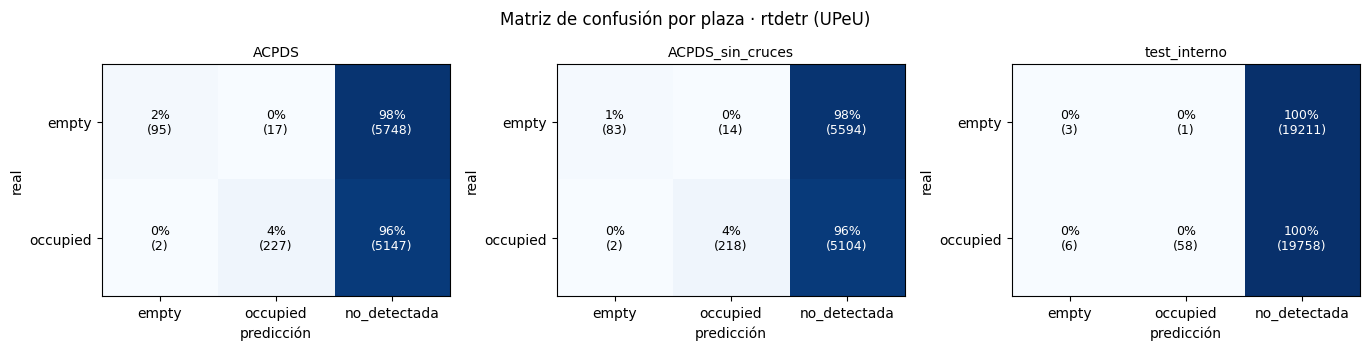

In [11]:
tablas = show_confusions(preds, f'Matriz de confusión por plaza · {MODELO} (UPeU)',
                         save_as=f'matriz_confusion_{MODELO}')

## 5.2 Gráfico de métricas

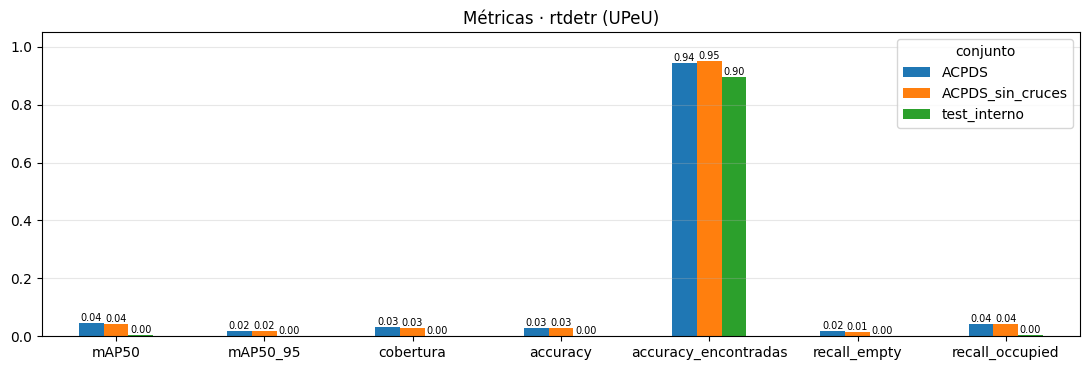

In [12]:
principal = metricas[metricas['dataset'] == '(todo)'].set_index('conjunto')
cols = ['mAP50', 'mAP50_95', 'cobertura', 'accuracy', 'accuracy_encontradas', 'recall_empty', 'recall_occupied']
ax = principal[cols].T.plot.bar(figsize=(11, 3.8), rot=0, ylim=(0, 1.05))
ax.set_title(f'Métricas · {MODELO} (UPeU)'); ax.grid(axis='y', alpha=.3); ax.legend(title='conjunto')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUTPUT}/metricas_{MODELO}.png', dpi=120); plt.show()

# 6. Diagnóstico de las plazas no detectadas (ACPDS)

Una plaza queda `no_detectada` si ninguna caja (score ≥ 0.5) la solapa al menos un 50 %. Puede ser porque el modelo **no la ve** (IoU ≈ 0) o porque **la ve con una caja distinta o con poca confianza**. El histograma y la tabla lo separan.

El resultado oficial sigue siendo el de IoU 0.5 y score 0.5: esto es análisis del error, no una forma de mejorar los números.

Plazas no detectadas en ACPDS: 10895 de 11236
count    10895.000
mean         0.010
std          0.052
min          0.000
25%          0.000
50%          0.000
75%          0.000
max          0.500
Name: iou, dtype: float64


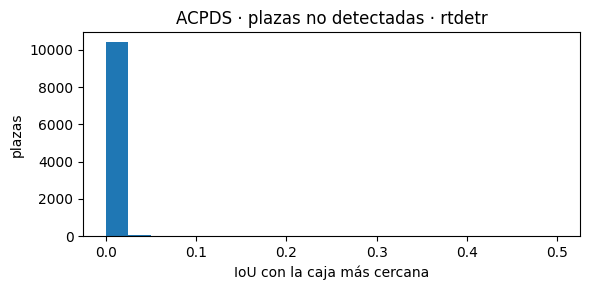

,iou_thr,score_thr,cobertura,accuracy,accuracy_encontradas
0,0.5,0.50,0.030,0.029,0.944
1,0.5,0.25,0.040,0.038,0.943
2,0.4,0.50,0.036,0.033,0.918
3,0.4,0.25,0.049,0.045,0.919
4,0.3,0.50,0.042,0.037,0.871
5,0.3,0.25,0.058,0.051,0.881
6,0.2,0.50,0.053,0.044,0.825
7,0.2,0.25,0.073,0.061,0.831


In [13]:
t = spot_table(acpds_test, preds, **CONFIG['spot_eval'])
nd = t[t['prediccion'] == 'no_detectada']
print(f'Plazas no detectadas en ACPDS: {len(nd)} de {len(t)}')
print(nd['iou'].describe().round(3))

plt.figure(figsize=(6, 3))
plt.hist(nd['iou'], bins=20, range=(0, 0.5))
plt.xlabel('IoU con la caja más cercana'); plt.ylabel('plazas'); plt.title(f'ACPDS · plazas no detectadas · {MODELO}')
plt.tight_layout(); plt.savefig(f'{OUTPUT}/diagnostico_iou_{MODELO}.png', dpi=120); plt.show()

filas = []
for iou_thr in [0.5, 0.4, 0.3, 0.2]:
    for score_thr in [0.5, 0.25]:
        m = spot_metrics(spot_table(acpds_test, preds, iou_thr=iou_thr, score_thr=score_thr))
        filas.append({'iou_thr': iou_thr, 'score_thr': score_thr, **m})
diagnostico = pd.DataFrame(filas)
display(diagnostico[['iou_thr', 'score_thr', 'cobertura', 'accuracy', 'accuracy_encontradas']].round(3))

## 6.1 (Opcional) ¿Mejora con más resolución?

El modelo se entrenó a 640 píxeles. Si el problema es el tamaño de las plazas, con 1280 debería encontrar más. Más lento: en CPU, mejor no ejecutarlo.

In [ ]:
RUN_1280 = False

if RUN_1280:
    preds_1280 = predict(acpds_test + test_interno, batch_size=8, imgsz=1280, desc=f'{MODELO} @1280:')
    metricas_1280 = evaluate_sets(preds_1280, EVAL_SETS, f'{MODELO} (UPeU) @1280')
    cols = ['modelo', 'conjunto', 'dataset', 'mAP50', 'cobertura', 'accuracy_encontradas', 'accuracy']
    display(pd.concat([metricas, metricas_1280])[cols].sort_values(['conjunto', 'dataset']).round(3))
    metricas_1280.to_csv(f'{OUTPUT}/metricas_{MODELO}_1280.csv', index=False)

# 7. Ejemplos visuales

Verde = predicción `empty`, rojo = `occupied` (score ≥ 0.5). Gris discontinuo = plaza real que el modelo no encuentra.

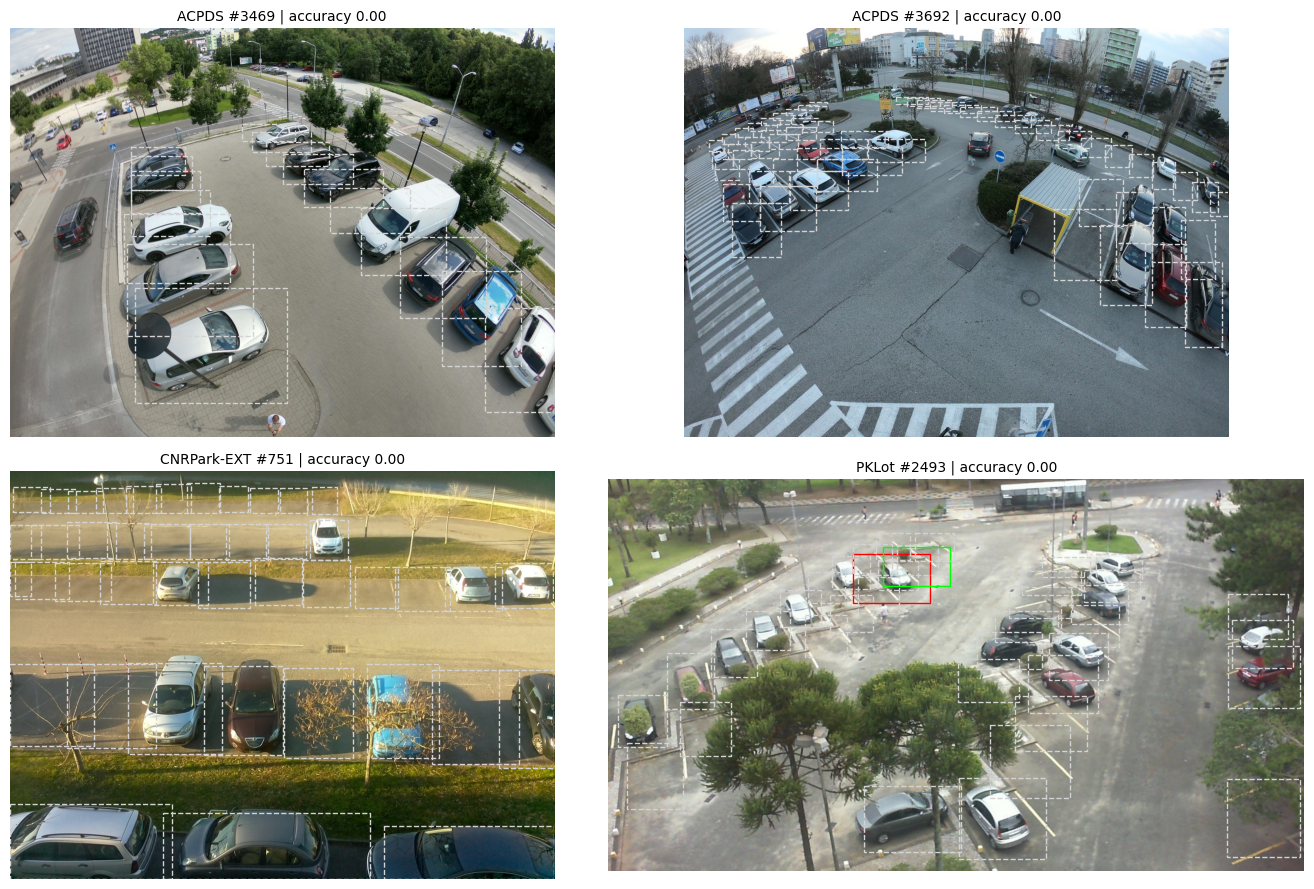

In [14]:
def draw(ax, photo, preds, title):
    ax.imshow(load_image(photo))
    table = spot_table([photo], preds, **CONFIG['spot_eval'])
    ok = (table['real'] == table['prediccion']).mean()
    for r in preds:
        if r['image_id'] == photo.id and r['score'] >= CONFIG['spot_eval']['score_thr']:
            x, y, w, h = r['bbox']
            ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, lw=1,
                                            ec='lime' if r['category_id'] == 1 else 'red'))
    missed = set(table.loc[table['prediccion'] == 'no_detectada', 'spot_id'])
    for s in photo.spots:
        if s.id in missed:
            x, y, w, h = s.bbox
            ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, lw=1, ec='lightgray', ls='--'))
    ax.set_title(f'{title} | accuracy {ok:.2f}', fontsize=10); ax.axis('off')


ejemplos = random.Random(1).sample(acpds_test, 2) + random.Random(1).sample(test_interno, 2)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, p in zip(axes.ravel(), ejemplos):
    draw(ax, p, preds, f'{p.dataset} #{p.id}')
plt.tight_layout(); plt.savefig(f'{OUTPUT}/ejemplos_{MODELO}.png', dpi=100); plt.show()

# 8. Guardar resultados

Mismo formato que `results/pretrained_models/yolo11/`: detecciones, plazas, métricas y matriz de confusión, con el nombre del modelo como sufijo.

In [15]:
pd.DataFrame(preds).to_csv(f'{OUTPUT}/detecciones_{MODELO}.csv', index=False)
pd.concat([tb.assign(conjunto=n) for n, tb in tablas.items()]).to_csv(f'{OUTPUT}/plazas_{MODELO}.csv', index=False)
metricas.to_csv(f'{OUTPUT}/metricas_{MODELO}.csv', index=False)
diagnostico.to_csv(f'{OUTPUT}/diagnostico_umbral_{MODELO}.csv', index=False)
with open(f'{OUTPUT}/config_{MODELO}.json', 'w') as f:
    json.dump({**CONFIG, 'dataset_sha': DATASET_SHA, 'acpds_fotos': len(acpds_test),
               'test_interno_fotos': len(test_interno)}, f, indent=2, default=str)

print('Archivos en', OUTPUT)
for f in sorted(Path(OUTPUT).iterdir()):
    print(f'  {f.name:42s} {f.stat().st_size / 1e6:6.2f} MB')

Archivos en /content/results/pretrained_models/rtdetr
  config_rtdetr.json                           0.00 MB
  detecciones_rtdetr.csv                       1.57 MB
  diagnostico_iou_rtdetr.png                   0.02 MB
  diagnostico_umbral_rtdetr.csv                0.00 MB
  ejemplos_rtdetr.png                          1.94 MB
  matriz_confusion_rtdetr.csv                  0.00 MB
  matriz_confusion_rtdetr.png                  0.05 MB
  metricas_rtdetr.csv                          0.00 MB
  metricas_rtdetr.png                          0.04 MB
  plazas_rtdetr.csv                            4.36 MB


En Colab, esta celda comprime la carpeta con la ruta `results/pretrained_models/rtdetr/` dentro y la descarga. Al descomprimirla queda una carpeta `results` que se puede arrastrar tal cual a la raíz del repositorio en GitHub (**Add file → Upload files**).

In [16]:
if IN_COLAB:
    import shutil
    from google.colab import files
    zip_path = shutil.make_archive(f'/content/resultados_{MODELO}', 'zip', root_dir='/content',
                                   base_dir=f'results/pretrained_models/{MODELO}')
    files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 9. Conclusiones

- **Cobertura:** el modelo casi no encuentra plazas en nuestros datos: 3,0 % en ACPDS, 0,4 % en CNRPark-EXT y 0 % en PKLot (IoU 0,5, score 0,5).
- **Clasificación:** cuando encuentra una plaza, la clasifica bien (accuracy de las encontradas: 0,94 en ACPDS y 0,90 en el test interno). Casi no hay confusión entre libre y ocupada.
- **Resultado global:** accuracy 0,029 y mAP50 0,044 en ACPDS. El cuello de botella es localizar, no clasificar.
- **Clases:** encuentra más plazas ocupadas que libres (recall 0,042 frente a 0,016 en ACPDS). Un coche es más fácil de detectar que unas líneas en el suelo.
- **Diagnóstico:** casi todas las plazas no detectadas en ACPDS tienen IoU 0 (mediana 0). Con los criterios más permisivos (IoU 0,2, score 0,25) la cobertura solo llega al 7,3 %. No es un problema de umbrales ni de formato de las cajas: el modelo no reconoce nuestras escenas.
- **Conclusión:** un detector de plazas entrenado en otro aparcamiento no se puede usar tal cual en el nuestro. Es la línea base que justifica hacer fine-tuning con nuestros datos.